In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

# EDA

In [2]:
df = pd.read_csv("crop_disease_dataset.csv")
df

,crop_type,region,season,soil_type,irrigation_method,temperature_C,humidity_percent,rainfall_mm,leaf_wetness_hrs,soil_pH,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,days_since_last_rain,plant_age_days,pesticide_applied,fertilizer_kg_ha,disease_label
0,maize,NaN,Kharif,Clay,FLOOD,26.209077,NaN,101.582272,14.009117,7.085974,39.893186,58.936746,44.894035,NaN,22.0,0.0,53.719785,Fungal
1,Cotton,Central,Rabi,NaN,Sprinkler,33.430687,58.979548,30.296413,11.067606,6.190607,179.824571,88.881893,71.394673,8.0,13.0,0.0,92.819906,Pest Damage
2,cotton,NaN,NaN,CLAY,Drip,28.047989,62.103653,90.564280,21.470657,6.224184,89.690594,17.839237,55.877176,5.0,31.0,0.0,68.282729,Bacterial
3,Soybean,North,Rabi,NaN,NaN,31.411229,54.430551,16.922677,19.309367,6.925993,143.060345,62.503022,91.410148,49.0,116.0,0.0,62.743722,Bacterial
4,cotton,NaN,kharif,sandy,FLOOD,22.822997,56.975619,NaN,12.402934,NaN,134.998574,80.448392,57.815445,29.0,84.0,0.0,84.100232,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,Soybean,East,RABI,NaN,FLOOD,37.517744,62.230582,10.447007,18.876040,6.840942,101.929372,9.629340,64.154966,19.0,87.0,1.0,46.424884,Pest Damage
4996,cotton,South,Kharif,CLAY,Flood,23.903747,60.444864,14.374015,21.000930,6.931124,89.441427,27.306649,113.679945,48.0,48.0,1.0,54.569977,Healthy
4997,Wheat,South,Zaid,sandy,drip,27.540218,NaN,41.363295,4.628891,6.521855,117.870657,86.290999,109.897459,2.0,11.0,0.0,49.246413,Fungal
4998,Rice,West,NaN,Sandy,drip,35.715673,45.102924,58.812460,3.616925,6.549429,144.167112,70.383208,79.230487,33.0,107.0,0.0,NaN,Pest Damage


In [3]:
df.shape
df.dtypes
Missing_Counts = df.isna().sum().to_frame("Null Counts") #df.isnull().sum()
Missing_Counts["Null Percent"] = (Missing_Counts["Null Counts"] / len(df) * 100)
Missing_Counts.sort_values("Null Counts",ascending = False)

,Null Counts,Null Percent
season,1405,28.10
irrigation_method,1215,24.30
soil_type,1125,22.50
region,1057,21.14
temperature_C,250,5.00
rainfall_mm,250,5.00
fertilizer_kg_ha,200,4.00
humidity_percent,200,4.00
nitrogen_kg_ha,200,4.00
days_since_last_rain,200,4.00


In [3]:
categorial_col = ["crop_type", "region", "season", "soil_type", "irrigation_method", "disease_label"] # list variable
for x in categorial_col:
    print(x)
    print(sorted(df[x].dropna().unique())) #Here it was sorting all categorial columns & removes missing values [this removes any row that has at least one NaN value anywhere in it.] -> Only uniques

crop_type
['Cotton', 'Maize', 'Rice', 'Soybean', 'WHEAT', 'Wheat', 'cotton', 'maize', 'rice']
region
['Central', 'East', 'North', 'SOUTH', 'South', 'West', 'north']
season
['Kharif', 'RABI', 'Rabi', 'Zaid', 'kharif']
soil_type
['CLAY', 'Clay', 'Loamy', 'Sandy', 'Silty', 'loamy', 'sandy']
irrigation_method
['Drip', 'FLOOD', 'Flood', 'Rainfed', 'Sprinkler', 'drip']
disease_label
['Bacterial', 'Fungal', 'Healthy', 'Pest Damage']


In [5]:
class_disease = df["disease_label"].count() # Gives overall count of rows
class_disease = df["disease_label"].value_counts() # Gives counts based on categories
balance = (class_disease / class_disease.sum() * 100).round(2).astype(str) + "%" # To avoid TypeError: unsupported operand type(s) for +: 'float' and 'str'
balance #balance.index used to check order

disease_label
Healthy        30.62%
Bacterial      25.06%
Fungal         24.34%
Pest Damage    19.98%
Name: count, dtype: object

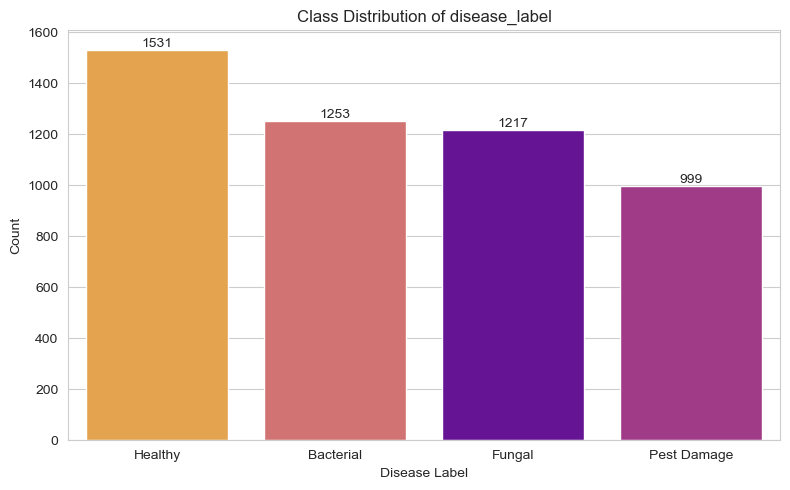

In [8]:
balance
a = sns.countplot(data = df, x = "disease_label", order = balance.index, hue="disease_label", palette = "plasma", legend = False)
# Seaborn (sns) — often plots multiple categories at once (multiple bars, multiple boxplots, multiple lines by group), so it uses palette= to assign a range/set of colors, one per category
for container in a.containers:
    a.bar_label(container)
plt.title("Class Distribution of disease_label")
plt.xlabel("Disease Label")
plt.ylabel("Count")
plt.tight_layout() # automatically adjusts the spacing in your figure so that titles, axis labels, and subplots don't overlap or get cut off.  
plt.show()


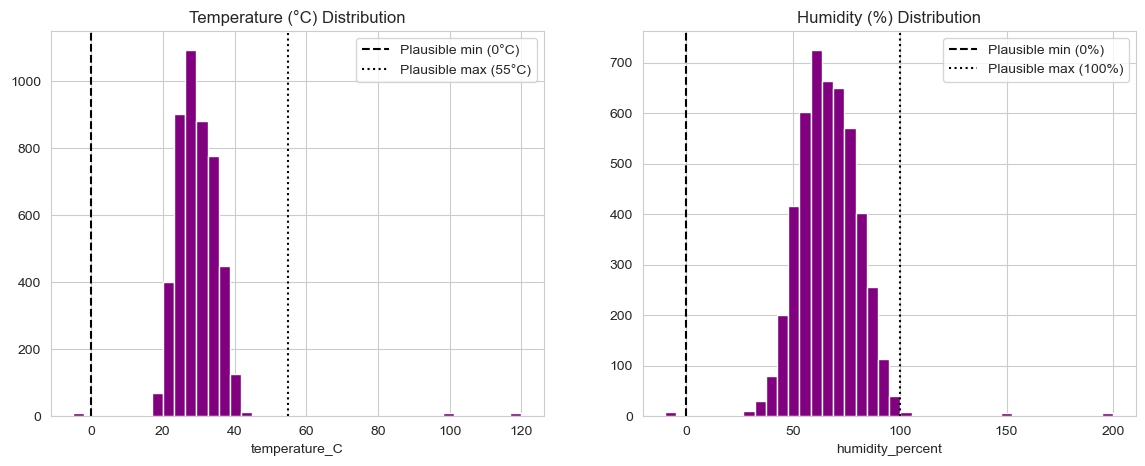

In [9]:
df[["humidity_percent","temperature_C"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # Used to print 2plots side by side & axes[0] - left , axes[1] -  right
axes[0].hist(df["temperature_C"].dropna(), bins = 40, color = 'purple', edgecolor = 'white') # removed missing values with dropna
axes[0].set_title("Temperature (°C) Distribution")
axes[0].set_xlabel("temperature_C")
axes[0].axvline(0, color="black", linestyle="--", label="Plausible min (0°C)") # "axis vertical line" — draws a vertical line at x = 0 on that subplot
axes[0].axvline(55, color="black", linestyle=":", label="Plausible max (55°C)")
axes[0].legend()

axes[1].hist(df["humidity_percent"].dropna(), bins = 40, color = 'purple', edgecolor = 'white') # removed missing values with dropna
axes[1].set_title("Humidity (%) Distribution")
axes[1].set_xlabel("humidity_percent")
axes[1].axvline(0, color="black", linestyle="--", label="Plausible min (0%)")
axes[1].axvline(100, color="black", linestyle=":", label="Plausible max (100%)")
axes[1].legend()
plt.show()

C:\Users\ammul\AppData\Local\Temp\ipykernel_11808\2577708233.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="disease_label", y="soil_pH", palette="Set2")


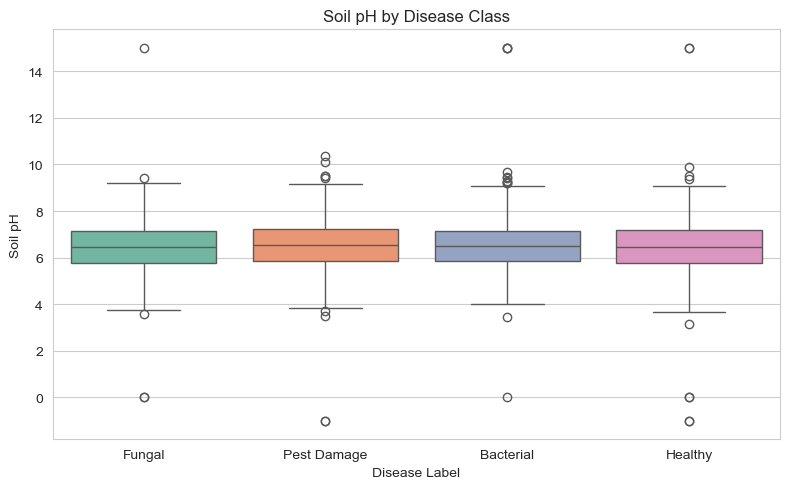

,count,mean,std,min,25%,50%,75%,max
disease_label,,,,,,,,
Bacterial,1199.0,6.507636,1.087593,0.0,5.852219,6.496460,7.144838,15.000000
Fungal,1180.0,6.471006,1.078830,0.0,5.781093,6.454498,7.147579,15.000000
Healthy,1462.0,6.472897,1.118072,-1.0,5.755784,6.469682,7.183703,15.000000
Pest Damage,961.0,6.524101,1.075623,-1.0,5.841758,6.522064,7.229772,10.360089


In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="disease_label", y="soil_pH", palette="Set2")
# To avoid error use sns.boxplot(data=df, x="disease_label",hue = "disease_label",legend = False, y="soil_pH", palette="Set2")
plt.title("Soil pH by Disease Class")
plt.xlabel("Disease Label")
plt.ylabel("Soil pH")
plt.tight_layout()
plt.show()
df.groupby("disease_label")["soil_pH"].describe()

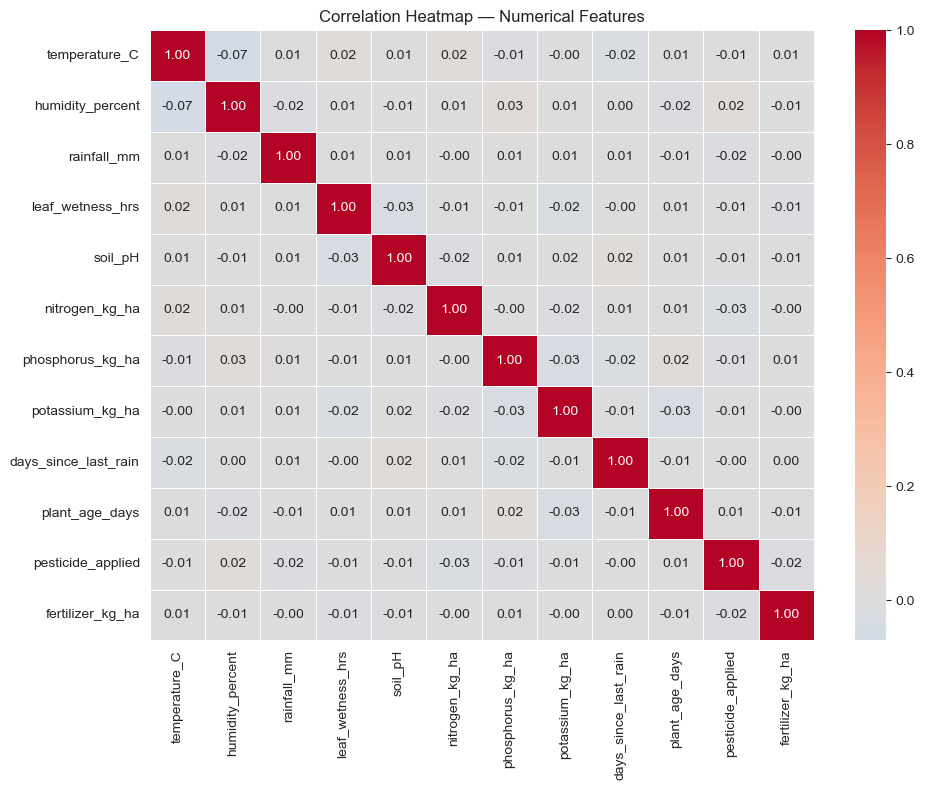

Top correlated pairs:
temperature_C     humidity_percent   -0.070740
humidity_percent  temperature_C      -0.070740
soil_pH           leaf_wetness_hrs   -0.034596
leaf_wetness_hrs  soil_pH            -0.034596
potassium_kg_ha   plant_age_days     -0.033506
plant_age_days    potassium_kg_ha    -0.033506
dtype: float64


In [11]:
num_cols = ["temperature_C", "humidity_percent", "rainfall_mm", "leaf_wetness_hrs",
            "soil_pH", "nitrogen_kg_ha", "phosphorus_kg_ha", "potassium_kg_ha",
            "days_since_last_rain", "plant_age_days", "pesticide_applied", "fertilizer_kg_ha"]

corr = df[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()
corr_pairs = corr.where(~np.eye(len(corr), dtype=bool)).unstack().dropna()
corr_pairs = corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)
print("Top correlated pairs:")
print(corr_pairs.head(6))

# Data Cleaning

In [12]:
categorial_col = ["crop_type", "region", "season", "soil_type", "irrigation_method"] 
for y in categorial_col:
    df[y] = df[y].astype("string").str.strip().str.title()

# disease_label is the target — standardise casing too, but keep "Pest Damage" as-is
df["disease_label"] = df["disease_label"].astype("string").str.strip().str.title()
for y in categorial_col + ["disease_label"]:
    print(y, "->", sorted(df[y].dropna().unique()))


crop_type -> ['Cotton', 'Maize', 'Rice', 'Soybean', 'Wheat']
region -> ['Central', 'East', 'North', 'South', 'West']
season -> ['Kharif', 'Rabi', 'Zaid']
soil_type -> ['Clay', 'Loamy', 'Sandy', 'Silty']
irrigation_method -> ['Drip', 'Flood', 'Rainfed', 'Sprinkler']
disease_label -> ['Bacterial', 'Fungal', 'Healthy', 'Pest Damage']


In [13]:
# Domain-knowledge valid ranges
valid_ranges = {
    "temperature_C": (0, 55),
    "humidity_percent": (0, 100),
    "rainfall_mm": (0, 500),          # extreme weekly rainfall cap
    "leaf_wetness_hrs": (0, 24),      # cannot exceed hours in a day
    "soil_pH": (3, 10),               # as stated in the data dictionary
    "nitrogen_kg_ha": (0, 300),
    "phosphorus_kg_ha": (0, 200),
    "potassium_kg_ha": (0, 300),
    "days_since_last_rain": (0, 60),
    "plant_age_days": (0, 200),
    "fertilizer_kg_ha": (0, 300),
}

before_counts = {}
for col, (lo, hi) in valid_ranges.items():
    mask = ~df[col].between(lo, hi) & df[col].notna()
    before_counts[col] = mask.sum()
    df.loc[mask, col] = np.nan

pd.Series(before_counts, name="values_set_to_NaN").sort_values(ascending=False).to_frame()


,values_set_to_NaN
fertilizer_kg_ha,51
humidity_percent,34
temperature_C,30
rainfall_mm,25
soil_pH,17
phosphorus_kg_ha,4
potassium_kg_ha,2
nitrogen_kg_ha,1
leaf_wetness_hrs,0
days_since_last_rain,0


In [14]:
from scipy.stats import skew
from scipy.stats import skew

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if "pesticide_applied" in numeric_cols:
    numeric_cols.remove("pesticide_applied")  # treat separately (binary -> mode)

skew_vals = df[numeric_cols].skew().abs().sort_values(ascending=False)
print("Absolute skewness per numeric column:")
print(skew_vals)

Absolute skewness per numeric column:
rainfall_mm             1.940765
temperature_C           0.169370
fertilizer_kg_ha        0.059757
soil_pH                 0.052276
potassium_kg_ha         0.035720
plant_age_days          0.017108
phosphorus_kg_ha        0.016286
humidity_percent        0.016268
days_since_last_rain    0.013637
leaf_wetness_hrs        0.013442
nitrogen_kg_ha          0.000253
dtype: float64


In [15]:
# Rule: |skew| > 0.5 -> median (robust to skew/outliers), else -> mean (roughly symmetric)
SKEW_THRESHOLD = 0.5

for col in numeric_cols:
    col_skew = df[col].skew()
    if abs(col_skew) > SKEW_THRESHOLD:
        fill_value = df[col].median()
        method = "median"
    else:
        fill_value = df[col].mean()
        method = "mean"
    df[col] = df[col].fillna(fill_value)
    print(f"{col:25s} skew={col_skew:6.2f} -> imputed with {method} ({fill_value:.2f})")

# Binary column -> mode
mode_val = df["pesticide_applied"].mode()[0]
df["pesticide_applied"] = df["pesticide_applied"].fillna(mode_val)
print(f"\npesticide_applied -> imputed with mode ({mode_val})")

# Categorical columns -> mode
for c in categorial_col:
    mode_val = df[c].mode()[0]
    df[c] = df[c].fillna(mode_val)
    print(f"{c:20s} -> imputed with mode ('{mode_val}')")

print("\nRemaining missing values after imputation:")
print(df.isna().sum().sum())


temperature_C             skew=  0.17 -> imputed with mean (29.43)
humidity_percent          skew=  0.02 -> imputed with mean (66.27)
rainfall_mm               skew=  1.94 -> imputed with median (27.92)
leaf_wetness_hrs          skew= -0.01 -> imputed with mean (12.03)
soil_pH                   skew=  0.05 -> imputed with mean (6.49)
nitrogen_kg_ha            skew=  0.00 -> imputed with mean (120.15)
phosphorus_kg_ha          skew=  0.02 -> imputed with mean (60.33)
potassium_kg_ha           skew=  0.04 -> imputed with mean (80.36)
days_since_last_rain      skew=  0.01 -> imputed with mean (29.29)
plant_age_days            skew=  0.02 -> imputed with mean (64.26)
fertilizer_kg_ha          skew=  0.06 -> imputed with mean (50.77)

pesticide_applied -> imputed with mode (1.0)
crop_type            -> imputed with mode ('Wheat')
region               -> imputed with mode ('North')
season               -> imputed with mode ('Kharif')
soil_type            -> imputed with mode ('Loamy')
irriga

# FE

In [16]:
# HTI - Humidity Temperature Index
df["HTI"] = (df["humidity_percent"] * df["temperature_C"])/100
df[["humidity_percent","temperature_C","HTI"]].head()

,humidity_percent,temperature_C,HTI
0,66.268640,26.209077,17.368399
1,58.979548,33.430687,19.717268
2,62.103653,28.047989,17.418826
3,54.430551,31.411229,17.097305
4,56.975619,22.822997,13.003544


In [17]:
df["drought_stress"] = ((df["days_since_last_rain"] > 20) & (df["rainfall_mm"] < 10)).astype(int)
df["drought_stress"].value_counts()

drought_stress
0    4309
1     691
Name: count, dtype: int64

In [18]:
RANDOM_STATE = 42 # 42 is just a number to start if from can choose any value instead
np.random.seed(RANDOM_STATE)

def maturity_bucket(days):
    if days < 30:
        return "Seedling"
    elif days <= 70:
        return "Vegetative"
    else:
        return "Reproductive"

df["maturity_stage"] = df["plant_age_days"].apply(maturity_bucket)

maturity_order = {"Seedling": 0, "Vegetative": 1, "Reproductive": 2}
df["maturity_stage_encoded"] = df["maturity_stage"].map(maturity_order)

df[["plant_age_days", "maturity_stage", "maturity_stage_encoded"]].sample(8, random_state=RANDOM_STATE)


,plant_age_days,maturity_stage,maturity_stage_encoded
1501,20.000000,Seedling,0
2586,27.000000,Seedling,0
2653,43.000000,Vegetative,1
1055,41.000000,Vegetative,1
705,64.260825,Vegetative,1
106,87.000000,Reproductive,2
589,30.000000,Vegetative,1
2468,15.000000,Seedling,0


In [19]:
categorial_col = ["crop_type", "region", "season", "soil_type", "irrigation_method"]

df_encoded = pd.get_dummies(df, columns=categorial_col, drop_first=False)

print("Shape before OHE:", df.shape)
print("Shape after OHE :", df_encoded.shape)
df_encoded.head()


Shape before OHE: (5000, 22)
Shape after OHE : (5000, 38)


,temperature_C,humidity_percent,rainfall_mm,leaf_wetness_hrs,soil_pH,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,days_since_last_rain,plant_age_days,pesticide_applied,fertilizer_kg_ha,disease_label,HTI,drought_stress,maturity_stage,maturity_stage_encoded,crop_type_Cotton,crop_type_Maize,crop_type_Rice,crop_type_Soybean,crop_type_Wheat,region_Central,region_East,region_North,region_South,region_West,season_Kharif,season_Rabi,season_Zaid,soil_type_Clay,soil_type_Loamy,soil_type_Sandy,soil_type_Silty,irrigation_method_Drip,irrigation_method_Flood,irrigation_method_Rainfed,irrigation_method_Sprinkler
0,26.209077,66.268640,101.582272,14.009117,7.085974,39.893186,58.936746,44.894035,29.291667,22.0,0.0,53.719785,Fungal,17.368399,0,Seedling,0,False,True,False,False,False,False,False,True,False,False,True,False,False,True,False,False,False,False,True,False,False
1,33.430687,58.979548,30.296413,11.067606,6.190607,179.824571,88.881893,71.394673,8.000000,13.0,0.0,92.819906,Pest Damage,19.717268,0,Seedling,0,True,False,False,False,False,True,False,False,False,False,False,True,False,False,True,False,False,False,False,False,True
2,28.047989,62.103653,90.564280,21.470657,6.224184,89.690594,17.839237,55.877176,5.000000,31.0,0.0,68.282729,Bacterial,17.418826,0,Vegetative,1,True,False,False,False,False,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False
3,31.411229,54.430551,16.922677,19.309367,6.925993,143.060345,62.503022,91.410148,49.000000,116.0,0.0,62.743722,Bacterial,17.097305,0,Reproductive,2,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,True,False,False,False
4,22.822997,56.975619,27.915197,12.402934,6.492167,134.998574,80.448392,57.815445,29.000000,84.0,0.0,84.100232,Healthy,13.003544,0,Reproductive,2,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,False,True,False,False


# Model

In [20]:
# Drop the intermediate maturity_stage text column (we keep the encoded version)
model_df = df_encoded.drop(columns=["maturity_stage"])

X = model_df.drop(columns=["disease_label"])
y = model_df["disease_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))


Train shape: (4000, 36)  Test shape: (1000, 36)
disease_label
Healthy        0.306
Bacterial       0.25
Fungal         0.244
Pest Damage      0.2
Name: proportion, dtype: Float64


In [21]:
# Scale features for KNN (distance-based); trees are scale-invariant but scaling doesn't hurt them
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {}

# Decision Tree
dt = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=10)
dt.fit(X_train, y_train)
models["Decision Tree"] = (dt, X_train, X_test)

# KNN with k = 3, 5, 7
knn_results = {}
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_acc = accuracy_score(y_train, knn.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, knn.predict(X_test_scaled))
    knn_results[k] = (knn, train_acc, test_acc)
    print(f"KNN (k={k}) -> Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}")

best_k = max(knn_results, key=lambda k: knn_results[k][2])
print(f"\nBest k by test accuracy: k={best_k}")
models[f"KNN (k={best_k})"] = (knn_results[best_k][0], X_train_scaled, X_test_scaled)

# Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, max_depth=12)
rf.fit(X_train, y_train)
models["Random Forest"] = (rf, X_train, X_test)


KNN (k=3) -> Train Acc: 0.6950, Test Acc: 0.4030
KNN (k=5) -> Train Acc: 0.6540, Test Acc: 0.4270
KNN (k=7) -> Train Acc: 0.6462, Test Acc: 0.4720

Best k by test accuracy: k=7


In [22]:
reports = {}
for name, (model, xtr, xte) in models.items():
    y_pred = model.predict(xte)
    print(f"\n===== {name} =====")
    report_str = classification_report(y_test, y_pred)
    print(report_str)
    reports[name] = classification_report(y_test, y_pred, output_dict=True)



===== Decision Tree =====
              precision    recall  f1-score   support

   Bacterial       0.48      0.43      0.46       251
      Fungal       0.66      0.66      0.66       243
     Healthy       0.69      0.85      0.76       306
 Pest Damage       0.71      0.57      0.64       200

    accuracy                           0.64      1000
   macro avg       0.64      0.63      0.63      1000
weighted avg       0.64      0.64      0.64      1000


===== KNN (k=7) =====
              precision    recall  f1-score   support

   Bacterial       0.32      0.41      0.36       251
      Fungal       0.47      0.47      0.47       243
     Healthy       0.60      0.66      0.63       306
 Pest Damage       0.54      0.27      0.36       200

    accuracy                           0.47      1000
   macro avg       0.48      0.45      0.45      1000
weighted avg       0.49      0.47      0.47      1000


===== Random Forest =====
              precision    recall  f1-score   support

Macro F1 by model: {'Decision Tree': 0.6286, 'KNN (k=7)': 0.4532, 'Random Forest': 0.6517}
Best model: Random Forest


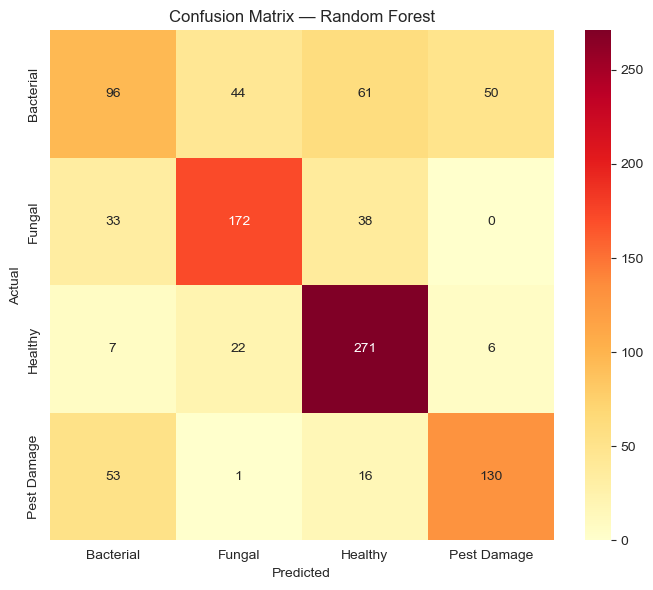

In [23]:
# Pick the best model by macro F1
macro_f1_scores = {name: rep["macro avg"]["f1-score"] for name, rep in reports.items()}
best_model_name = max(macro_f1_scores, key=macro_f1_scores.get)
print("Macro F1 by model:", {k: round(v, 4) for k, v in macro_f1_scores.items()})
print("Best model:", best_model_name)

best_model, xtr_b, xte_b = models[best_model_name]
y_pred_best = best_model.predict(xte_b)

labels_order = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_best, labels=labels_order)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrRd", xticklabels=labels_order, yticklabels=labels_order)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [24]:
# Identify the most confused pair (excluding the diagonal)
off_diag = cm.copy().astype(float)
np.fill_diagonal(off_diag, 0)
max_pos = np.unravel_index(off_diag.argmax(), off_diag.shape)
print(f"Most confused pair: Actual='{labels_order[max_pos[0]]}' predicted as '{labels_order[max_pos[1]]}' "
      f"({int(off_diag[max_pos])} cases)")


Most confused pair: Actual='Bacterial' predicted as 'Healthy' (61 cases)


In [25]:
comparison_rows = []
for name, (model, xtr, xte) in models.items():
    train_acc = accuracy_score(y_train, model.predict(xtr))
    test_acc = accuracy_score(y_test, model.predict(xte))
    macro_f1 = reports[name]["macro avg"]["f1-score"]
    comparison_rows.append({
        "Model": name,
        "Train Acc": round(train_acc, 4),
        "Test Acc": round(test_acc, 4),
        "Macro F1": round(macro_f1, 4),
    })

comparison_table = pd.DataFrame(comparison_rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
comparison_table


,Model,Train Acc,Test Acc,Macro F1
0,Random Forest,0.9453,0.669,0.6517
1,Decision Tree,0.8818,0.642,0.6286
2,KNN (k=7),0.6462,0.472,0.4532


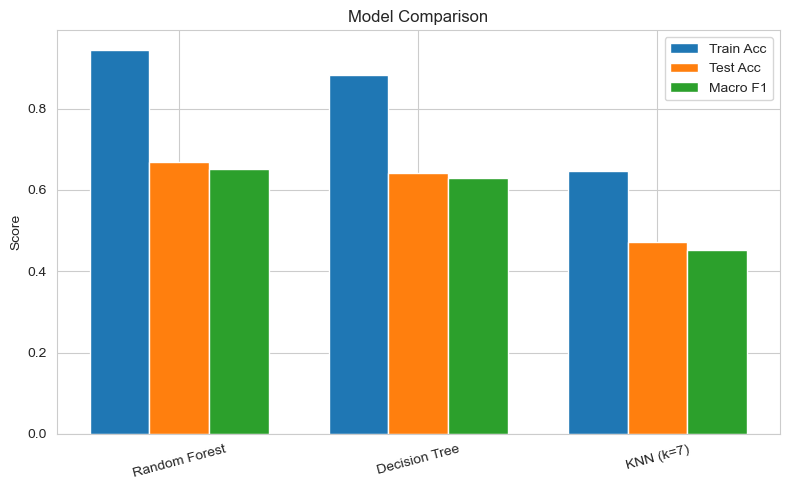

In [26]:
plt.figure(figsize=(8, 5))
x_pos = np.arange(len(comparison_table))
width = 0.25
plt.bar(x_pos - width, comparison_table["Train Acc"], width, label="Train Acc")
plt.bar(x_pos, comparison_table["Test Acc"], width, label="Test Acc")
plt.bar(x_pos + width, comparison_table["Macro F1"], width, label="Macro F1")
plt.xticks(x_pos, comparison_table["Model"], rotation=15)
plt.ylabel("Score")
plt.title("Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:
output_path = "crop_disease_dataset_cleaned.csv"
df_encoded.drop(columns=["maturity_stage"]).to_csv(output_path, index=False)
print(f"Saved cleaned & feature-engineered dataset to: {output_path}")
print("Final shape:", df_encoded.drop(columns=['maturity_stage']).shape)


Saved cleaned & feature-engineered dataset to: crop_disease_dataset_cleaned.csv
Final shape: (5000, 37)
